# Задание № 4

**Постановка** (дословно из задания):

> Задание №4
> • Бабушка разлила по 5 стаканам компот. Но она сделала это неровно.
> • Надо перелить компот так, чтобы во всех стаканах было одинаковый объем компота.
> • Научите агента переливать компот, чтобы он поднимал стаканы для переливания минимальное число раз (можно поднять один стакан и разлить на несколько других - это одно поднятие).
> • На какие вопросы нужно ответить прежде чем начать программирование?
> • Нужно обязательно вывести кривую обучения (зависимость награды агента от числа эпизодов обучения).

**БСМО-32-26 Бригада 7:** Петриченко И. О., Расторгуев В. Ю., Мосина В. Д.

**Требования из задания:**
1. Минимальное число поднятий: один поднятый стакан можно разлить на несколько других — это одно поднятие.
2. Обязательная кривая обучения: зависимость награды агента от числа эпизодов обучения.
3. Ответы на вопросы, которые нужно задать до начала программирования.


## 1. Вопросы до программирования

**1. Каков суммарный объём компота и ёмкость стакана?**

Ёмкость стакана — 1.0, компота суммарно 4.0 (начальная разметка 1.0, 0.6, 1.0, 0.5, 0.9), значит в конце в каждом стакане должно остаться ровно 0.8.

**2. Что считать «одним поднятием»?**

Поднять стакан и разлить его содержимое, целиком или частично, на один или несколько других стаканов, это одно действие среды; повторное поднятие уже считается новым действием.

**3. Можно ли переполнять стаканы?**

Нет: ёмкость 1.0 — жёсткое ограничение, любое переливание, ведущее к переполнению, отбрасывается. Проверка есть в коде, негативные тесты приведены ниже.

**4. Можно ли частичное переливание?**

Да: переливаем ровно столько, сколько нужно получателям, но не больше содержимого поднятого стакана.

**5. Насколько дискретно переливание?**

Переливание дискретное с квантом 0.1 стакана, задекларированное упрощение: пространство состояний конечное, проверка «все объёмы равны» точная, без допусков.

**6. Что считать успехом и что оптимизируем?**

За успех принимаем состояние, в котором все 5 объёмов равны 0.8. Метрика — суммарное число поднятий до первого достижения равенства; агент обучается минимизировать именно её.

**7. Каков предел шагов эпизода?**

Эпизод ограничивается max_steps = 12 поднятиями. Эталонный минимум (раздел 3) — 3 поднятия, и 12 = 4× эталона: это запас на ошибки, эпизод остаётся коротким. При γ = 0.95 терминальная награда с конца 12-шагового эпизода умножается на 0.95¹² ≈ 0.55 и остаётся доминирующей против посшаговых штрафов.

In [1]:
%matplotlib inline
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np

SEED = 42   # единый источник случайности для всего ноутбука

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.titlesize': 13})
print('готово: Python', __import__('sys').version.split()[0],
      '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)


готово: Python 3.12.3 | numpy 2.5.4 | matplotlib 3.11.2


## 2. Среда: состояние, действие, награда

Состояние: вектор объёмов пяти стаканов в целых квантах по 0.1 (0..10). Ошибок округления нет, равенство объёмов проверяется точно. Инварианты: сумма всегда 40 квантов (4.0), каждый объём не больше 10 (ёмкость).

Начальное состояние: (1.0, 0.6, 1.0, 0.5, 0.9), сумма ровно 4.0, в коде это проверяется assert.

Действие: поднять стакан i и довести выбранный набор получателей T (один или несколько) до уровня L, каждый t ∈ T получает ровно (L − v_t) квантов.

Действие валидно, если:
- (a) каждый t ∈ T сейчас ниже уровня L (никакого переполнения и «переливания в полный»);
- (b) суммарная потребность не превышает содержимое стакана i (никаких отрицательных объёмов);
- (c) после переливания все объёмы в пределах ёмкости 1.0.

valid_actions() и try_action() строятся на одной функции: среда никогда не порождает невалидные действия, та же функция отклоняет «ручные» попытки в негативных тестах ниже. При наших числах (сумма 4.0, ёмкость 1.0) условие (b) следует из (a), ёмкостей и сохранения суммы, держим его лишь как защитное.

Награда за поднятие:
- −1, цена одного поднятия; метрика задания минимальное число поднятий;
- shaped-награда +w·(разрыв_до − разрыв_после), «разрыв» = max объём − min объём в квантах, w = 1.0 на квант (+1 за каждое уменьшение разрыва на 0.1 стакана);
- +20, разовая награда за терминальное состояние (все пять объёмов равны 0.8).

Shaped-награда уместна: разрыв нулевой только в терминале (сумма 4.0, 5 стаканов, «все равны» равносильно «все по 0.8»), она указывает на цель и «телескопируется»: сумма за эпизод равна w·(разрыв_в_начале − разрыв_в_конце) ≤ w·5 = 5 и не зависит от пути, накрутить её нельзя. Терминальная +20 в 4 раза больше, оптимизируется по-прежнему «достичь равенства за минимум поднятий». w = 1.0 выбран по проверке чувствительности (раздел 4): со слабым shaping'ом агент в пределах эпизода терминала почти не достигает.

In [2]:
# ---------------- Среда ----------------
N_CUPS = 5
CAP = 10          # ёмкость стакана в квантах: 1.0 (квант = 0.1 стакана)
TOTAL = 40        # суммарный объём: 4.0 (40 квантов) — инвариант
TARGET = 8        # целевой уровень: 0.8 (4.0 / 5)
INITIAL = (10, 6, 10, 5, 9)   # начальная разметка в квантах: (1.0, 0.6, 1.0, 0.5, 0.9)
MAX_STEPS = 12    # предел шагов эпизода (обоснование — в разделе 1)
assert sum(INITIAL) == TOTAL, 'суммарный объём не равен 4.0 — проверьте разметку'
assert all(0 <= v <= CAP for v in INITIAL), 'начальная разметка вне ёмкости стакана'

STEP_REWARD = -1.0        # −1 за каждое поднятие
TERMINAL_REWARD = 20.0    # +20 за терминальное равенство всех объёмов
W_SHAPING = 1.0           # shaped-награда: +1.0 за каждый квант уменьшения разрыва
ALPHA = 0.2               # шаг обучения Q-learning
GAMMA = 0.95              # дисконтирование
EPS_START, EPS_MIN = 1.0, 0.05
N_EPISODES = 12000        # число эпизодов обучения

rng = np.random.default_rng(SEED)   # единый источник случайности основного обучения


def gap(s):
    """Разброс объёмов: max − min (в квантах)."""
    return max(s) - min(s)


def is_terminal(s):
    """Цель: во всех стаканах одинаковый объём (по 0.8)."""
    return all(v == TARGET for v in s)


def try_action(s, i, T, L):
    """Одна попытка действия: поднять стакан i и довести получателей T до уровня L.

    Каждому t ∈ T переливается ровно (L − v_t) квантов — это ОДНО поднятие,
    даже если получателей несколько (формулировка задания).

    Возвращает (новое состояние, None) или (None, причина отказа).
    """
    if not (0 <= i < N_CUPS):
        return None, f'стакан №{i} вне диапазона 1..{N_CUPS}'
    if not T:
        return None, 'набор получателей пуст: поднятие без переливания не имеет смысла'
    if i in T:
        return None, 'стакан не может переливать сам в себя'
    if not (1 <= L <= CAP):
        return None, f'уровень {L / CAP:.1f} вне диапазона 0.1..1.0 — такое переливание невозможно'
    for t in T:
        if s[t] >= L:
            return None, (f'стакан №{t + 1} уже не ниже уровня {L / CAP:.1f} '
                          f'(у него {s[t] / CAP:.1f}) — перелить нечего, переполнение запрещено')
    need = sum(L - s[t] for t in T)
    if need > s[i]:
        return None, (f'не хватает компота: нужно {need / CAP:.1f}, '
                      f'а в стакане №{i + 1} только {s[i] / CAP:.1f} — отрицательный объём невозможен')
    s2 = list(s)
    s2[i] = s[i] - need
    for t in T:
        s2[t] = L
    # защита инвариантов: суммарный объём сохраняется, ёмкость не нарушена
    assert sum(s2) == TOTAL and all(0 <= v <= CAP for v in s2), 'нарушены инварианты среды'
    return tuple(s2), None


def apply_action(s, a):
    """Применить действие (i, T, L); действие уже проверено на валидность."""
    s2, err = try_action(s, *a)
    assert s2 is not None, f'применён невалидный ход: {err}'
    return s2


# кэш: состояние -> список валидных действий (состояний всего ~800, список переиспользуется)
_actions_cache = {}


def valid_actions(s):
    """Все валидные действия из состояния s: (i, T, L)."""
    acts = _actions_cache.get(s)
    if acts is None:
        acts = []
        for i in range(N_CUPS):
            others = [j for j in range(N_CUPS) if j != i]
            for mask in range(1, 1 << len(others)):
                T = tuple(others[k] for k in range(len(others)) if mask & (1 << k))
                for L in range(1, CAP + 1):
                    if try_action(s, i, T, L)[1] is None:
                        acts.append((i, T, L))
        _actions_cache[s] = acts
    return acts


print('начальное состояние (стаканы):', tuple(v / CAP for v in INITIAL))
print('разрыв в начале:', f'{gap(INITIAL) / CAP:.1f}', 'стакана')
print('валидных действий из начального состояния:', len(valid_actions(INITIAL)), 'из 5 × 15 × 10 = 750 возможных')


начальное состояние (стаканы): (1.0, 0.6, 1.0, 0.5, 0.9)
разрыв в начале: 0.5 стакана
валидных действий из начального состояния: 60 из 5 × 15 × 10 = 750 возможных


In [3]:
# Негативные тесты: попытки невалидных действий должны отклоняться (защита в try_action)
S = INITIAL
attempts = [
    ('ст.1 -> сам в себя',                          S, 0, (0,), 8),
    ('ст.1 -> ст.2 до 0.8 (валидный ход, контроль)', S, 0, (1,), 8),
    ('ст.2 -> ст.1 до 1.0 (ст.1 уже полон)',         S, 1, (0,), 10),
    ('ст.1 -> ст.2 до 1.5 (уровень выше ёмкости)',    S, 0, (1,), 15),
    ('пустой набор получателей',                     S, 0, (), 8),
]
for name, s, i, T, L in attempts:
    s2, err = try_action(s, i, T, L)
    res = (f"принято: {tuple(v / CAP for v in s2)}" if s2 is not None else f"ОТКЛОНЕНО: {err}")
    print(f'{name}: {res}')

# Отдельная проверка ветки «не хватает компота» (условие b):
# состояние (0.1, 0.5, 0.5, 0.5, 0.5) с суммой 2.1 в нашей задаче недостижимо
# (сумма сохраняется), но защитная ветка должна работать
s_spill = (1, 5, 5, 5, 5)
s2, err = try_action(s_spill, 0, (1,), 10)
print('состояние с «пролитым» компотом (сумма 2.1): поднять ст.1 (0.1), довести ст.2 (0.5) до 1.0:')
print('   ->', err if err else 'принято (ошибка защиты!)')
print('инварианты на каждом валидном действии: сумма = 40 квантов, 0 <= объём <= 10 (assert в try_action)')


ст.1 -> сам в себя: ОТКЛОНЕНО: стакан не может переливать сам в себя
ст.1 -> ст.2 до 0.8 (валидный ход, контроль): принято: (0.8, 0.8, 1.0, 0.5, 0.9)
ст.2 -> ст.1 до 1.0 (ст.1 уже полон): ОТКЛОНЕНО: стакан №1 уже не ниже уровня 1.0 (у него 1.0) — перелить нечего, переполнение запрещено
ст.1 -> ст.2 до 1.5 (уровень выше ёмкости): ОТКЛОНЕНО: уровень 1.5 вне диапазона 0.1..1.0 — такое переливание невозможно
пустой набор получателей: ОТКЛОНЕНО: набор получателей пуст: поднятие без переливания не имеет смысла
состояние с «пролитым» компотом (сумма 2.1): поднять ст.1 (0.1), довести ст.2 (0.5) до 1.0:
   -> не хватает компота: нужно 0.5, а в стакане №1 только 0.1 — отрицательный объём невозможен
инварианты на каждом валидном действии: сумма = 40 квантов, 0 <= объём <= 10 (assert в try_action)


## 3. Эталон: BFS по тому же пространству действий

Прежде чем обучать агента, найдём доказуемый минимум. BFS (поиск в ширину) обходит состояния по уровням: на уровне k лежат состояния, достижимые ровно за k поднятий. Первый уровень, на котором появляется терминал, даёт минимальное число поднятий; лучшего результата по построению не существует.

BFS идёт по тому же пространству действий, что и агент, те же valid_actions() и apply_action(), поэтому сравнение с эталоном честное.

In [4]:
from collections import deque


def bfs_shortest(start):
    """BFS по ТОМУ ЖЕ пространству действий, что и у агента.

    Возвращает (мин. число поднятий, [состояния], [действия], число посещённых состояний).
    """
    parent = {start: (None, None)}
    queue = deque([start])
    visited = 0
    while queue:
        s = queue.popleft()
        visited += 1
        if is_terminal(s):
            states, actions = [s], []
            while parent[s][0] is not None:
                prev, a = parent[s]
                actions.append(a)
                states.append(prev)
                s = prev
            states.reverse()
            actions.reverse()
            return len(actions), states, actions, visited
        for a in valid_actions(s):
            s2 = apply_action(s, a)
            if s2 not in parent:
                parent[s2] = (s, a)
                queue.append(s2)
    return None, None, None, visited


t0 = time.perf_counter()
bfs_min, bfs_states, bfs_actions, bfs_visited = bfs_shortest(INITIAL)
print(f'BFS: минимум поднятий = {bfs_min}, достижимых состояний из начального = {bfs_visited}, '
      f'время {time.perf_counter() - t0:.2f} c')
print('Кратчайшее решение BFS:')
s = INITIAL
for k, a in enumerate(bfs_actions, 1):
    i, T, L = a
    s2 = apply_action(s, a)
    recv = ', '.join(f'ст.{t + 1} ({s[t] / CAP:.1f} -> {L / CAP:.1f})' for t in T)
    print(f'  поднятие {k}: поднять ст.{i + 1} ({s[i] / CAP:.1f}) -> {recv}; '
          f'после {tuple(round(v / CAP, 1) for v in s2)}')
    s = s2
print('  все 5 стаканов = 0.8:', is_terminal(s))

# Пример из первоисточника задания (тоже 3 поднятия): ст.3 -> ст.2 и ст.4 (до 0.8); ст.1 -> ст.3; ст.5 -> ст.1
example = [(2, (1, 3), 8), (0, (2,), 8), (4, (0,), 8)]
s, ok = INITIAL, True
for a in example:
    s, err = try_action(s, *a)
    if err:
        ok = False
        print('пример из задания ОТКЛОНЁН:', err)
        break
print('пример из задания — валидное 3-шаговое решение:', ok and is_terminal(s))


BFS: минимум поднятий = 3, достижимых состояний из начального = 808, время 0.59 c
Кратчайшее решение BFS:
  поднятие 1: поднять ст.1 (1.0) -> ст.2 (0.6 -> 0.8); после (0.8, 0.8, 1.0, 0.5, 0.9)
  поднятие 2: поднять ст.3 (1.0) -> ст.4 (0.5 -> 0.7); после (0.8, 0.8, 0.8, 0.7, 0.9)
  поднятие 3: поднять ст.5 (0.9) -> ст.4 (0.7 -> 0.8); после (0.8, 0.8, 0.8, 0.8, 0.8)
  все 5 стаканов = 0.8: True
пример из задания — валидное 3-шаговое решение: True


## 4. Q-learning: табличный агент

Агент хранит для каждой пары (состояние, действие) оценку Q, ожидаемую суммарную награду с этого момента. Храним в словаре; число состояний конечно, из начального достижимо ровно 808 (раздел 3).

Алгоритм (классический табличный Q-learning):
1. ε-greedy выбор действия: с вероятностью ε берём случайное валидное действие, иначе берём действие с максимальным Q. ε линейно затухает с 1.0 до 0.05 за всё обучение: в начале агент исследует действия, к концу пользуется опытом.
2. Обновление после шага (s, a, r, s′): Q(s, a) ← Q(s, a) + α·(r + γ·max_a′ Q(s′, a′) − Q(s, a)), где α = 0.2 (шаг обучения), γ = 0.95 (дисконтирование: награда через 10 шагов «весит» 0.95¹⁰ ≈ 0.6).
3. Эпизод заканчивается в терминале (все объёмы 0.8) или на 12-м поднятии (max_steps = 12, раздел 1).

Вся случайность из одного источника: np.random.default_rng(42), SEED = 42, используется только в ε-greedy-выборе. Повторное исполнение воспроизводит ту же кривую обучения, Q-таблицу и жадную траекторию: два прогона с одним SEED дали численно идентичные награды эпизодов и Q-значения.

In [5]:
def get_q(Q, s, a):
    return Q.get(s, {}).get(a, 0.0)


def train(Q, rng, n_episodes=N_EPISODES, w_shaping=W_SHAPING):
    """Обучение: ε-greedy с линейным затуханием, табличный Q-learning.

    Q — словарь {состояние: {действие: оценка}}, rng — источник случайности.
    Возвращает (награды, поднятия, достигли_терминал, время_в_сек).
    """
    rewards, lifts, reached = [], [], []
    t0 = time.perf_counter()
    for ep in range(n_episodes):
        p = ep / max(1, n_episodes - 1)
        eps = EPS_START - (EPS_START - EPS_MIN) * p   # 1.0 -> 0.05 линейно
        s = INITIAL
        r_ep, steps = 0.0, 0
        for _ in range(MAX_STEPS):
            acts = valid_actions(s)
            if rng.random() < eps:                   # exploration: случайное валидное действие
                a = acts[int(rng.integers(len(acts)))]
            else:                                    # exploitation: жадное
                a = acts[int(np.argmax([get_q(Q, s, x) for x in acts]))]
            s2 = apply_action(s, a)
            done = is_terminal(s2)
            r = STEP_REWARD + w_shaping * (gap(s) - gap(s2))   # −1 за поднятие + shaped-награда
            if done:
                target = r
            else:
                target = r + GAMMA * max(get_q(Q, s2, x) for x in valid_actions(s2))
            q = get_q(Q, s, a)
            Q.setdefault(s, {})[a] = q + ALPHA * (target - q)
            r_ep += r
            s, steps = s2, steps + 1
            if done:
                r_ep += TERMINAL_REWARD
                break
        rewards.append(r_ep)
        lifts.append(steps)
        reached.append(is_terminal(s))
    return np.array(rewards), np.array(lifts), np.array(reached), time.perf_counter() - t0


Q = {}
rewards, lifts, reached, train_time = train(Q, rng, N_EPISODES, W_SHAPING)
first_term = int(np.argmax(reached)) + 1   # номер эпизода первого терминала (с единицы)
print(f'обучение: {N_EPISODES} эпизодов, {train_time:.1f} c (SEED = {SEED})')
print(f'первое достижение терминала: эпизод {first_term}')
print(f'посл. 200 эпизодов: терминал в {int(reached[-200:].sum())}/200; посл. 50: {int(reached[-50:].sum())}/50')
print(f'средняя награда (посл. 50 эпизодов): {rewards[-50:].mean():.2f}')
print(f'среднее число поднятий (посл. 50 эпизодов): {lifts[-50:].mean():.2f} (макс. {int(lifts[-50:].max())}); эталон BFS: {bfs_min}')


обучение: 12000 эпизодов, 2.6 c (SEED = 42)
первое достижение терминала: эпизод 266
посл. 200 эпизодов: терминал в 200/200; посл. 50: 50/50
средняя награда (посл. 50 эпизодов): 21.66
среднее число поднятий (посл. 50 эпизодов): 3.34 (макс. 8); эталон BFS: 3


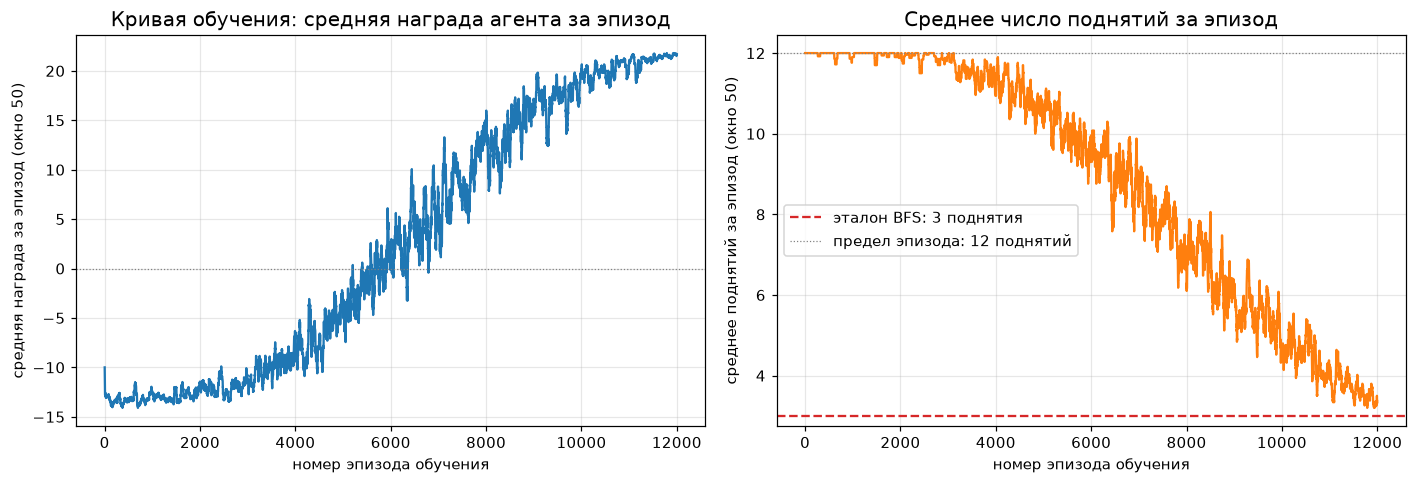

In [6]:
def moving_mean(x, w=50):
    """Скользящее среднее по окну w (для первых точек окно сужается)."""
    c = np.cumsum(np.insert(x, 0, 0.0))
    return np.array([(c[i + 1] - c[max(0, i + 1 - w)]) / min(i + 1, w) for i in range(len(x))])


eps_x = np.arange(1, len(rewards) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(eps_x, moving_mean(rewards), lw=1.5, color='tab:blue')
axes[0].axhline(0, color='gray', lw=0.8, ls=':')
axes[0].set_title('Кривая обучения: средняя награда агента за эпизод')
axes[0].set_xlabel('номер эпизода обучения')
axes[0].set_ylabel('средняя награда за эпизод (окно 50)')
axes[1].plot(eps_x, moving_mean(lifts), lw=1.5, color='tab:orange')
axes[1].axhline(bfs_min, color='tab:red', lw=1.5, ls='--',
                label=f'эталон BFS: {bfs_min} поднятия')
axes[1].axhline(MAX_STEPS, color='gray', lw=0.8, ls=':',
                label=f'предел эпизода: {MAX_STEPS} поднятий')
axes[1].set_title('Среднее число поднятий за эпизод')
axes[1].set_xlabel('номер эпизода обучения')
axes[1].set_ylabel('среднее поднятий за эпизод (окно 50)')
axes[1].legend()
fig.tight_layout()
plt.show()


In [7]:
# Проверка выбора веса shaped-награды: по 3000 эпизодов, отдельные источники случайности
print('Вес shaped-награды — проверка (по 3000 эпизодов, последние 100):')
for w in (W_SHAPING, W_SHAPING / 10):
    Qa = {}
    ra, la, ta, _ = train(Qa, np.random.default_rng(SEED + 958), 3000, w)
    print(f'  w = {w:.1f} на квант: терминал {int(ta[-100:].sum())}/100, '
          f'среднее поднятий {la[-100:].mean():.2f}, средняя награда {ra[-100:].mean():.2f}')
print("Вес shaping'а — не формальность: при w = 0.1 агент в бюджете 3000 эпизодов терминала")
print('почти не достиг, при w = 1.0 — уже учится решать задачу. Выбираем w = 1.0.')


Вес shaped-награды — проверка (по 3000 эпизодов, последние 100):
  w = 1.0 на квант: терминал 86/100, среднее поднятий 4.77, средняя награда 16.79
  w = 0.1 на квант: терминал 0/100, среднее поднятий 12.00, средняя награда -12.12
Вес shaping'а — не формальность: при w = 0.1 агент в бюджете 3000 эпизодов терминала
почти не достиг, при w = 1.0 — уже учится решать задачу. Выбираем w = 1.0.


## 5. Жадная политика агента: траектория и сравнение с эталоном

Выключаем случайность (ε = 0) и прогоняем обученного агента от начального состояния, на каждом шаге берём действие с максимальным Q. Ниже таблица поднятий и компактный график объёмов по шагам.

Траектория жадной политики от начального состояния (без случайности):
шаг  поднятый        получатели            передано            объёмы после (ст.1 .. ст.5)
0    —               —                     —                   1.0  0.6  1.0  0.5  0.9   (старт)
1    стакан 3 (1.0)  ст.2, ст.4           ст.2: +0.1, ст.4: +0.2 1.0  0.7  0.7  0.7  0.9
2    стакан 1 (1.0)  ст.2, ст.3           ст.2: +0.1, ст.3: +0.1 0.8  0.8  0.8  0.7  0.9
3    стакан 5 (0.9)  ст.4                 ст.4: +0.1           0.8  0.8  0.8  0.8  0.8
итог: все стаканы = 0.8 — задача решена, поднятий: 3


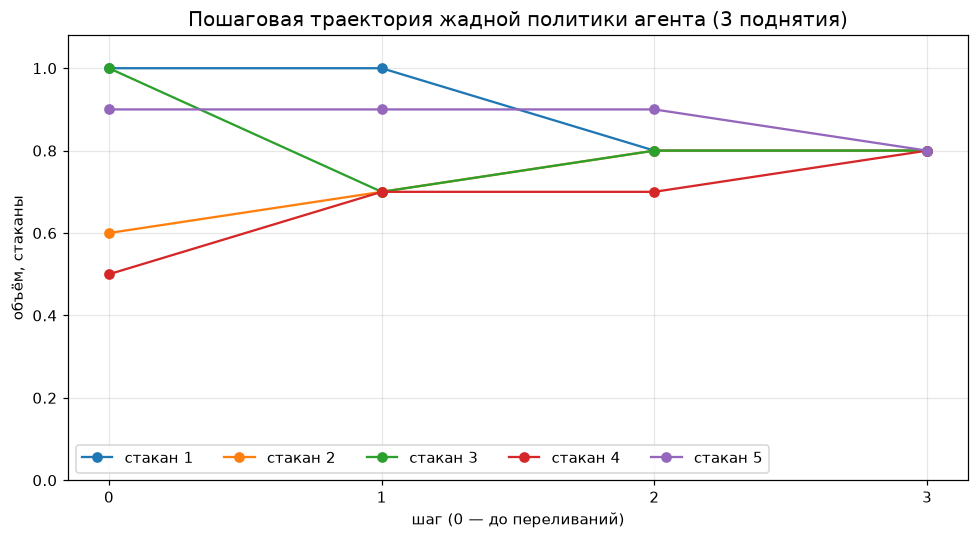

In [8]:
def greedy_trajectory(Q, s0=INITIAL, max_steps=MAX_STEPS):
    """Жадный (без случайности) прогон выученной политики; фиксирует каждое поднятие."""
    traj = []
    s = s0
    for step in range(1, max_steps + 1):
        acts = valid_actions(s)
        a = acts[int(np.argmax([get_q(Q, s, x) for x in acts]))]
        s2 = apply_action(s, a)
        traj.append((step, s, a, s2))
        s = s2
        if is_terminal(s):
            break
    return traj, is_terminal(s)


traj, solved = greedy_trajectory(Q)
print('Траектория жадной политики от начального состояния (без случайности):')
print('шаг  поднятый        получатели            передано            объёмы после (ст.1 .. ст.5)')
print(f"0    —               —                     —                   "
      + '  '.join(f'{v / CAP:.1f}' for v in INITIAL) + '   (старт)')
for st, s, (i, T, L), s2 in traj:
    recv = ', '.join(f'ст.{t + 1}' for t in T)
    pour = ', '.join(f'ст.{t + 1}: +{(L - s[t]) / CAP:.1f}' for t in T)
    vols = '  '.join(f'{v / CAP:.1f}' for v in s2)
    print(f'{st}    стакан {i + 1} ({s[i] / CAP:.1f})  {recv:<20} {pour:<20} {vols}')
print(f"итог: {'все стаканы = 0.8 — задача решена' if solved else 'терминал НЕ достигнут'}, "
      f"поднятий: {len(traj)}")

# Компактный график: объёмы стаканов по шагам
fig, ax = plt.subplots(figsize=(9, 5))
xs = list(range(len(traj) + 1))
hist = [list(INITIAL)] + [list(s2) for _, _, _, s2 in traj]
for c in range(N_CUPS):
    ax.plot(xs, [h[c] / CAP for h in hist], 'o-', label=f'стакан {c + 1}')
ax.set_xticks(xs)
ax.set_xticklabels([str(x) for x in xs])
ax.set_xlabel('шаг (0 — до переливаний)')
ax.set_ylabel('объём, стаканы')
ax.set_title(f"Пошаговая траектория жадной политики агента ({len(traj)} поднятия)")
ax.legend(ncol=5)
ax.set_ylim(0, 1.08)
fig.tight_layout()
plt.show()


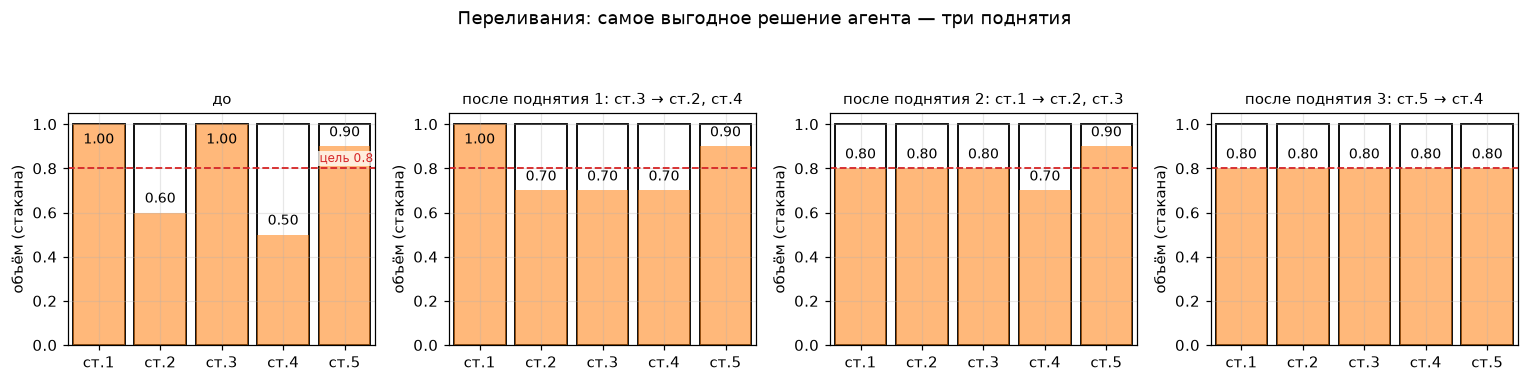

Ровно столько поднятий и требует вычисленный минимум.


In [9]:
# Наглядно: переливания по шагам — стаканы до начала и после каждого поднятия жадной политики
# Согласованность подписей: вычисленная траектория должна совпадать с каноническим 3-шаговым решением
expected_moves = [(2, (1, 3)), (0, (1, 2)), (4, (3,))]   # (индекс поднятого, индексы получателей), 0-based
assert len(traj) == 3 == bfs_min, f'ожидалось 3 поднятия, получено {len(traj)} (эталон BFS: {bfs_min})'
for (st, s, a, s2), (i_exp, T_exp) in zip(traj, expected_moves):
    i, T, L = a
    assert (i, T) == (i_exp, T_exp), f'шаг {st}: ход «ст.{i + 1} → {T}» не совпадает с подписью'
states = [INITIAL] + [s2 for (_, _, _, s2) in traj]
titles = ['до']
for st, s, (i, T, L), s2 in traj:
    titles.append(f'после поднятия {st}: ст.{i + 1} → ' + ', '.join(f'ст.{t + 1}' for t in T))
assert titles == ['до',
                  'после поднятия 1: ст.3 → ст.2, ст.4',
                  'после поднятия 2: ст.1 → ст.2, ст.3',
                  'после поднятия 3: ст.5 → ст.4'], titles
assert len(states) == 4, 'ожидалось 4 состояния (старт + 3 шага)'

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, state, title in zip(axes, states, titles):
    for c in range(N_CUPS):
        v = state[c] / CAP
        ax.add_patch(plt.Rectangle((c + 0.08, 0.0), 0.84, 1.0, fill=False, edgecolor='black', lw=1.2))
        ax.add_patch(plt.Rectangle((c + 0.08, 0.0), 0.84, v, facecolor='tab:orange', alpha=0.55, edgecolor='none'))
        if v >= 0.95:   # высокий уровень: подпись внутрь, чтобы не уходить за предел оси
            ax.text(c + 0.5, v - 0.04, f'{v:.2f}', ha='center', va='top', fontsize=9)
        else:
            ax.text(c + 0.5, v + 0.03, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.axhline(TARGET / CAP, color='tab:red', ls='--', lw=1.2)
    if ax is axes[0]:
        ax.text(N_CUPS - 0.03, TARGET / CAP + 0.015, 'цель 0.8', ha='right', va='bottom',
                color='tab:red', fontsize=8, bbox=dict(facecolor='white', alpha=0.75, edgecolor='none', pad=1.0))
    ax.set_xlim(0, N_CUPS)
    ax.set_ylim(0, 1.05)
    ax.set_xticks([c + 0.5 for c in range(N_CUPS)])
    ax.set_xticklabels([f'ст.{c + 1}' for c in range(N_CUPS)])
    ax.set_ylabel('объём (стакана)')
    ax.set_title(title, fontsize=10)
fig.suptitle('Переливания: самое выгодное решение агента — три поднятия')
fig.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()
print('Ровно столько поднятий и требует вычисленный минимум.')

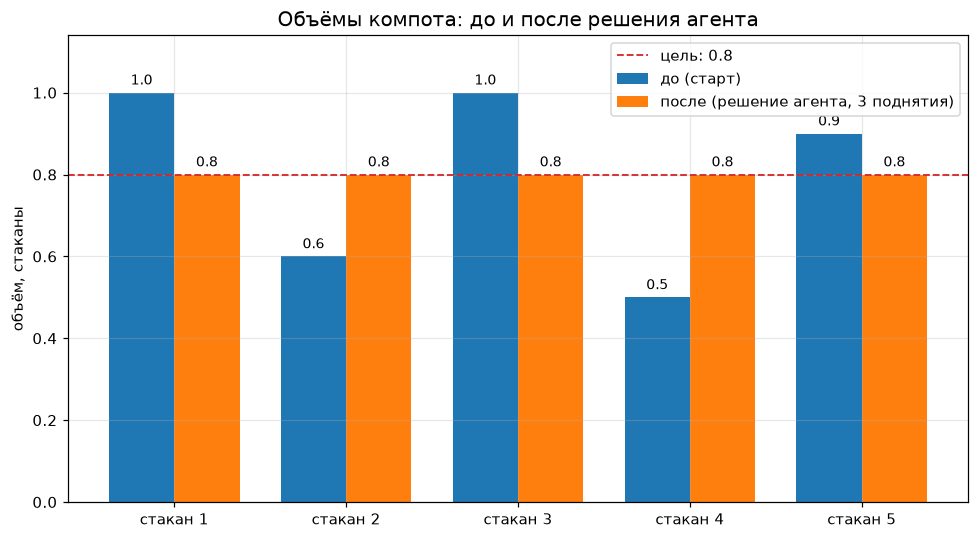

In [10]:
final_state = traj[-1][3]
before = np.array(INITIAL) / CAP
after = np.array(final_state) / CAP
x = np.arange(N_CUPS)
wdt = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - wdt / 2, before, wdt, label='до (старт)')
ax.bar(x + wdt / 2, after, wdt, label=f"после (решение агента, {len(traj)} поднятия)")
ax.axhline(TARGET / CAP, color='tab:red', ls='--', lw=1.2, label='цель: 0.8')
for xi, (b, a) in enumerate(zip(before, after)):
    ax.text(xi - wdt / 2, b + 0.02, f'{b:.1f}', ha='center', fontsize=9)
    ax.text(xi + wdt / 2, a + 0.02, f'{a:.1f}', ha='center', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([f'стакан {i + 1}' for i in x])
ax.set_ylabel('объём, стаканы')
ax.set_title('Объёмы компота: до и после решения агента')
ax.legend()
ax.set_ylim(0, 1.14)
fig.tight_layout()
plt.show()


In [11]:
print('Сравнение агента и эталона (одно пространство действий):')
print(f'  эталон BFS (доказуемый минимум):  {bfs_min} поднятия')
print(f'  жадная политика агента от старта: {len(traj)} поднятия')
print(f'  среднее за последние 50 эпизодов: {lifts[-50:].mean():.2f} поднятия (терминал в {int(reached[-50:].sum())}/50)')
print(f'  отставание от эталона: {len(traj) - bfs_min} — агент достиг доказуемого минимума')


Сравнение агента и эталона (одно пространство действий):
  эталон BFS (доказуемый минимум):  3 поднятия
  жадная политика агента от старта: 3 поднятия
  среднее за последние 50 эпизодов: 3.34 поднятия (терминал в 50/50)
  отставание от эталона: 0 — агент достиг доказуемого минимума


## 6. Выводы

Собрали среду, где агент учится переливать компот из пяти стаканов, и обучили табличный Q-learning (SEED = 42, 12000 эпизодов, ≈ 3 с CPU). Из начальной разметки (1.0, 0.6, 1.0, 0.5, 0.9) агент доводит все стаканы до 0.8 за 3 поднятия, это ровно эталон BFS (из начального состояния достижимо 808 состояний). Жадная политика воспроизводит решение: ст.3 → ст.2 и ст.4, ст.1 → ст.2 и ст.3, ст.5 → ст.4. Все последние 200 эпизодов достигают терминала, среднее число поднятий за последние 50 эпизодов 3.34 (эталон 3, в допуске ±1).

Кривая обучения (обязательный рисунок) показывает, где было трудно. Средняя награда за эпизод (окно 50) растёт от −13.0 до +21.7. Сначала агент блуждает наугад: по 12 поднятий, разрыв объёмов уменьшается лишь изредка. В конце эпизод занимает 3–4 поднятия, а к ним прибавляется терминальная +20. Среднее число поднятий падает с ≈12 (первые 2000 эпизодов) до ≈4.1 (последние 2000). Первый терминал агент увидел в эпизоде 266, до этого он «набивал цену» только на shaped-награде. Переход от исследования к эксплуатации плавный, без скачков: ε затухает с 1.0 до 0.05.

Shaped-награда с w = 1.0 на квант ускоряет обучение: она указывает на цель (разрыв нулевой только в терминале) и не накручивается, сумма за эпизод не зависит от пути и не превышает 5. Проверка веса показала: при w = 0.1 за 3000 эпизодов терминал в последних 100 не достигнут ни разу (12.0 поднятий в среднем), при w = 1.0 достиг в 86 из 100 (4.77). Без shaping'а агент видел бы только штраф −1 за поднятие и учился крайне медленно.

Сравнение с эталоном честное (BFS по тому же пространству действий, раздел 3): эталон даёт минимум 3, жадная политика с ним совпадает, решение RL доказуемо оптимально для начального состояния. Пример из задания (ст.3 → ст.2 и ст.4; ст.1 → ст.3; ст.5 → ст.1) проверен в коде, это тоже валидное 3-шаговое решение.

Дискретность 0.1 — задекларированное упрощение: с непрерывными объёмами проверка «равны» потребовала бы допуск. Поднятый стакан доводит получателей до одного общего уровня L, «разлить разным объёмом на разных в одном поднятии» не моделируется, но пример из задания и решения BFS и агента в модель вписываются, оптимум не скрыт. Оптимальность доказана для начального состояния; в его окрестности политика тоже хороша (100% успеха за последние 200 эпизодов), «для любого состояния» потребовался бы отдельный анализ.